In [7]:
# so here's the deal
# I am currently about 13 hours into this project.
# and now I need to transition stuff over to a notebook .
# first lets create one for the MLP that just shows how to run it
# as well as some different results, so I can have a neat write up.
# then we can switch over to the CNN architecture.



In [ ]:
# IMPORTS
import matplotlib.pyplot as pl
import pandas as pd

In [ ]:
def build_master_df(projections_path, reports_path):
  proj = pd.read_csv(projections_path)
  rep = pd.read_csv(reports_path)

  proj = proj[proj["projection"] == "Frontal"]
  df = proj.merge(rep[["uid", "findings", "impression", "Problems", "indication"]], on="uid", how="inner")

  # new label - 0 if normal, 1 if abnormal
  def label_from_text(row):
    # don't put everythign in there, just a little bit.
    text = str(row.get("Problems", "")).lower().strip()
    return 0 if text == "normal" else 1

  df["abnormal_label"] = df.apply(label_from_text, axis=1)

  # print(df["abnormal_label"].value_counts())
  # print(df["abnormal_label"].value_counts(normalize=True))


  return df

In [ ]:
def plot_training_curves(losses_train, errors_train, mode, model_type):
    epochs = range(1, len(losses_train) + 1) # sp we start 1 and end at the right number
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5)) # make subplots baby

    # --- loss curve ---
    ax1.plot(epochs, losses_train, label='Train Loss', color='steelblue')
    # rolling average to show the trend through the noise
    window = 5
    rolling_avg = np.convolve(losses_train, np.ones(window)/window, mode='valid')
    ax1.plot(range(window, len(losses_train)+1), rolling_avg,
             label=f'{window}-epoch rolling avg', color='red', linewidth=2)
    ax1.set_title('Training Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('BCE Loss')
    ax1.legend()
    ax1.grid(alpha=0.3)

    # --- error curve ---
    ax2.plot(epochs, errors_train, label='Train Error %', color='orange')
    rolling_err = np.convolve(errors_train, np.ones(window)/window, mode='valid')
    ax2.plot(range(window, len(errors_train)+1), rolling_err,
             label=f'{window}-epoch rolling avg', color='red', linewidth=2)
    ax2.set_title('Training Error Rate')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Error %')
    ax2.legend()
    ax2.grid(alpha=0.3)

    title = f"MLP training curves, mode {mode}, model {model_type}"
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    # plt.savefig('mlp_training_curves.png', dpi=150)
    plt.show()

In [ ]:
# All of the MLP stuf we could possible need. 
import torch, torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.optim.lr_scheduler import StepLR
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import fbeta_score
import spacy # small model, don't throw it on GPU.
from tokenizationProcess import get_clean_stuff, build_nlp_pipeline
from imblearn.over_sampling import SMOTE
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset, DataLoader

probability_flag = 0.50


class MLP(nn.Module):
    def __init__(self, input_nodes=500): # this is specified by the number of keywords that we need.
        super(MLP, self).__init__()

        self.network = nn.Sequential(
            # block 1
            nn.Linear(input_nodes, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            # another one
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            # convert it to output.
            nn.Linear(128, 1),
            # nn.Sigmoid()  # don't use this if you switch to BCEwithLogits, sigmoid already there.
        )

    # using nn.sequential makes this look much neater.
    def forward(self, x):
        return self.network(x)        # gree hee hee.


# using HE initilization for now.
def weights_init(layer_in):
    if isinstance(layer_in, nn.Linear):
        nn.init.kaiming_normal_(layer_in.weight)
        layer_in.bias.data.fill_(0.0)

def create_x_stuff(df, mode):
    nlp = build_nlp_pipeline()
    num_epochs = 200

    # creates X and Y based on penumonia values and the DF.
    print("starting the model creation process ")
    # this returns X and y as df's to try and use them in the train test split and dataloaders. Don't think its working as intended.

    # this uses a tokenizer to create a better representation of X and Y.

    X, y, df = get_clean_stuff(df, nlp, mode)  # returns a clean X and y that we will need for training later.

    # print("Here is our shape ", X.shape)
    # print("Post conversion")

    # now I gotta create data loaders. Bleh.
    X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
    # NOW we apply smote to prevent data leakage.
    # gonna try adding smote.
    smote = SMOTE(random_state=42)  # trying to fix some class imbalance

    X_train_bal, y_train_bal = smote.fit_resample(X_train_raw, y_train_raw)

    # print(f"Before SMOTE: {X.shape[0]} samples, {y.sum()} positive")
    # print(f"After SMOTE:  {X_train_bal.shape[0]} samples, {y_train_bal.sum()} positive")

    # we GOTTA turn these back into tensors before torch notices!
    X_train = torch.tensor(X_train_bal, dtype=torch.float32)
    y_train = torch.tensor(y_train_bal, dtype=torch.float32)
    X_test = torch.tensor(X_test_raw, dtype=torch.float32)
    y_test = torch.tensor(y_test_raw, dtype=torch.float32)

    return X_train, y_train, X_test, y_test, X, df


def create_mlp_model(df, mode, model_type):
    X_train, y_train, X_test, y_test, X, df = create_x_stuff(df, mode)
    num_epochs = 200

    if model_type == "single":
        model, errors_train, errors_test, losses_train, losses_test = create_mlp(X, X_train, y_train, X_test, y_test,
                                                                                 num_epochs)

    # gonna be honest... you're probably not super worth running.
    elif model_type == "ensemble":
        model, errors_train, errors_test, losses_train, losses_test = create_mlp_ensemble(X, X_train, y_train, X_test, y_test,
                                                                                 num_epochs)
    else:
        print("something not right")
        model, errors_train, errors_test, losses_train, losses_test = create_mlp(X, X_train, y_train, X_test, y_test,
                                                                                 num_epochs)


    # lets try to get a rough idea of where we are.


    return model, errors_train, errors_test, losses_train, losses_test  # get everything back.

def create_mlp(X, X_train, y_train, X_test, y_test, num_epochs):

    input_nodes = X.shape[1]
    model = MLP(input_nodes)
    data_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=100, shuffle=True,
                             worker_init_fn=np.random.seed(1))

    errors_train, errors_test, losses_train, losses_test = train_mlp(model, data_loader, y_train, num_epochs)

    # lets try to get a rough idea of where we are.
    evaluate_mlp(model, X_test, y_test)

    return model, errors_train, errors_test, losses_train, losses_test  # get everything back.


def create_mlp_ensemble(X, X_train, y_train, X_test, y_test, num_epochs):
    all_probs = []
    num_models = 5

    for i in range(num_models):
        print("training model ", i)

        model = MLP(input_nodes=X_train.shape[1])
        loader = DataLoader(TensorDataset(X_train, y_train), batch_size=100, shuffle=True,)

        train_mlp(model, loader, y_train, num_epochs)
        model.eval()
        with torch.no_grad():
            probs = torch.sigmoid(model(X_test).squeeze(1))
            all_probs.append(probs.numpy())

    ensemble_probs = np.mean(all_probs, axis=0)
    return ensemble_probs, None, None, None, None





# gonna try to add some weird anti overfitting check to it, watch out.
def train_mlp(model, data_loader, y_train, n_epoch=50, patience=5):

    print("Training MLP")
    # Initialize model weights
    model.apply(weights_init)

    # store the loss and the % correct at each epoch
    losses_train = np.zeros((n_epoch))
    errors_train = np.zeros((n_epoch))


    # choose cross entropy loss function (equation 5.24)
    # TRYING SOMETHING NEW SIRE
    n_neg = (y_train == 0).sum().item()
    n_pos = (y_train == 1).sum().item()
    pos_weight = torch.tensor(n_neg / n_pos)
    loss_function = nn.BCEWithLogitsLoss(pos_weight=pos_weight)  # trying a different loss function, we shall see.
    # construct SGD optimizer and initialize learning rate and momentum
    optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)
    # object that decreases learning rate by half every 10 epochs
    scheduler = StepLR(optimizer, step_size=10, gamma=0.5)

    # early stopping stuff coming in hot.
    best_loss = np.inf
    best_weights = None
    patience_counter = 0
    epochs_completed = 0

    for epoch in range(n_epoch):
      epochs_completed += 1
      model.train()
      epoch_loss = 0
      # loop over batches
      for i, batch in enumerate(data_loader):
        # retrieve inputs and labels for this batch
        x_batch, y_batch = batch
        # zero the parameter gradients
        optimizer.zero_grad()
        # forward pass -- calculate model output
        pred = model(x_batch).squeeze(1) # this is supposed to help
        # compute the loss
        loss = loss_function(pred, y_batch)
        # backward pass
        loss.backward()
        # SGD update
        optimizer.step()
        epoch_loss += loss.item()


      model.eval()
      with torch.no_grad():
          all_preds, all_labels = [], []
          for x_batch, y_batch in data_loader:
              pred = model(x_batch).squeeze(1)
              all_preds.append(pred)
              all_labels.append(y_batch)

      all_preds = torch.cat(all_preds)
      all_labels = torch.cat(all_labels)

      avg_loss = epoch_loss / len(data_loader)

      all_probs = torch.sigmoid(all_preds) # convert back to probabilities from logits in the loss function .

      predicted_class = (all_probs >= probability_flag).float() # threshold at 0.5
      accuracy = 100 * (predicted_class == all_labels).float().mean()

      losses_train[epoch] = avg_loss
      errors_train[epoch] = 100 - accuracy

      # early stopping check
      if avg_loss < best_loss - 1e-4: # as a place to start
          best_loss = avg_loss
          best_weights = model.state_dict().copy() # save our best weights as a checkpoint
          patience_counter = 0
      else:
          patience_counter += 1
          if patience_counter >= patience:
              # print(f"Early stopping requried sire. At epoch {epoch+1} — best loss: {best_loss:.4f}")
              model.load_state_dict(best_weights) # restore our previous best model
              # trim the zero padded tail off the arrays
              losses_train = losses_train[:epoch + 1]
              errors_train = errors_train[:epoch + 1]
              break


      model.train() # flip this back for the next epoch
      # tell scheduler to consider updating learning rate
      scheduler.step()

      # print(f"Epoch {epoch + 1:3d} | Loss: {avg_loss:.4f} | Train Acc: {accuracy:.1f}%")

    return (errors_train[:epochs_completed],
            errors_train[:epochs_completed],
            losses_train[:epochs_completed],
            losses_train[:epochs_completed])



def evaluate_mlp(model, x_test, y_test):
    print("************************************")
    model.eval()
    with torch.no_grad():
        logits = model(x_test).squeeze(1)
        preds  = torch.sigmoid(logits)
        predicted_class = (preds >= probability_flag).float()

    acc = 100 * (predicted_class == y_test).float().mean().item()
    auc = roc_auc_score(y_test.numpy(), preds.numpy())

    # this is what actually matters
    cm = confusion_matrix(y_test.numpy(), predicted_class.numpy())
    tn, fp, fn, tp = cm.ravel()

    for threshold in [0.5, 0.3, 0.2, 0.1, 0.05]:
        predicted_class = (preds >= threshold).float()
        cm = confusion_matrix(y_test.numpy(), predicted_class.numpy())
        tn, fp, fn, tp = cm.ravel()
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        print(
            f"  t={threshold:.2f} | Sensitivity: {sensitivity:.1%} | Specificity: {specificity:.1%} | FN: {fn} | FP: {fp}")

    print(f"Test Accuracy : {acc:.1f}%")
    print(f"Test AUC-ROC  : {auc:.4f}")
    print(f"\nConfusion Matrix:")
    print(f"  True Negatives  (correctly said normal)   : {tn}")
    print(f"  False Positives (incorrectly flagged)      : {fp}")
    print(f"  False Negatives (missed abnormal cases)   : {fn}  ← this is the dangerous one")
    print(f"  True Positives  (correctly caught)         : {tp}")
    print(f"\nSensitivity (recall on positives): {tp/(tp+fn):.1%}")
    print(f"Specificity (recall on negatives): {tn/(tn+fp):.1%}")

    # say that missing a sick paitent is twice as bad as a false alarm
    # we can use this to try and skew things certian ways. Right now beta is set to 2.
    # beta = 2
    # for threshold in [0.50, 0.30, 0.20, 0.10, 0.05]:
    #     predicted_class = (preds >= threshold).float().numpy()
    #     f2 = fbeta_score(y_test.numpy(), predicted_class, beta=beta)
    #     print(f"t={threshold:.2f} | F2: {f2:.4f}")





In [ ]:
# TOKENIZATION SECTION
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

import spacy
from negspacy.negation import Negex
from negspacy.termsets import termset
import medspacy

# Tokenizatino through Negex, a better NLP model for text recognition.
def build_nlp_pipeline():
    nlp = spacy.load("en_core_web_sm")

    ts = termset("en_clinical")
    nlp.add_pipe("negex", config={"neg_termset": ts.get_patterns()})

    return nlp



def tokenize(text, nlp):
    doc = nlp(str(text).lower())
    tokens = [
        token.lemma_
        for token in doc
        if not token.is_stop # drop "the", "is", "a", etc.
        and not token.is_punct # drop punctuation
        and not token.is_space # drop whitespace
    ]
    return " ". join(tokens)

# negspacy flavor
def tokenize_with_negation(text, nlp):
    # instead of just returning tokens, prefix negated terms with NEG to TF-IDF treats them as distinc features.

    doc = nlp(str(text).lower())
    tokens = []

    for token in doc:
        # skip stopwords, punctuiation, whitespace
        if token.is_stop or token.is_punct or token.is_space:
            continue

        lemma = token.lemma_

        is_negated = False
        for ent in doc.ents:
            if token in ent and ent._.negex:
                is_negated = True
                break

        if is_negated:
            tokens.append(f"NEG_{lemma}")
        else:
            tokens.append(lemma)

    return " ". join(tokens)


# negex flavor
def get_clean_stuff(df, nlp, mode="sparse"):
    max_features = -1 # should brick if this doesn't go off correctly.

    if mode == "sparse":
        max_features = 200
        df["text"] = (df["indication"].fillna(""))

    if mode == "medium":
        max_features = 1000
        df["text"] = (
            df["indication"].fillna("") + " " +
            df["impression"].fillna("")
        )

    if mode == "full":
        max_features = 500
        df["text"] = (
            df["indication"].fillna("") + " " +
            df["findings"].fillna("") + " " +
            df["impression"].fillna("")
            # do NOT put problems in here. bad idea.
        )

    # df["text_clean"] = df["text"].apply(tokenize, nlp=nlp)
    df["text_clean"] = df["text"].apply(tokenize_with_negation, nlp=nlp)

    print("here are the amx featuerts ", max_features)

    vectorizer = TfidfVectorizer(
        max_features=max_features,
        ngram_range=(1, 3), # trigrams
        min_df=2, # ignore terms apearing only once
    )

    X = vectorizer.fit_transform(df["text_clean"]).toarray()
    y = df["abnormal_label"].values

    # X is now our feature matrix , where each row is a paitent, and each column is a wordweight
    return X, y, df # give those back to our other guy.
    # now that we have this, we should be able to feed this into the MLP.



In [ ]:
# PATHS YIPEEE

# this contains the metadata that we want for our MLP
projections_path = 'IU-xray/indiana_projections.csv'
# this contains the labelling we want for our image CNN
reports_path = 'IU-xray/indiana_reports.csv'
# and of course, the images
image_dir = 'IU-xray/images/images_normalized'

# CREATING THE DF
print("Creating the DF")
df = build_master_df(projections_path, reports_path)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
starting the model creation process 
here are the amx featuerts  200
Training MLP
************************************
  t=0.50 | Sensitivity: 53.5% | Specificity: 64.4% | FN: 226 | FP: 99
  t=0.30 | Sensitivity: 96.7% | Specificity: 12.9% | FN: 16 | FP: 242
  t=0.20 | Sensitivity: 99.0% | Specificity: 1.8% | FN: 5 | FP: 273
  t=0.10 | Sensitivity: 100.0% | Specificity: 0.0% | FN: 0 | FP: 278
  t=0.05 | Sensitivity: 100.0% | Specificity: 0.0% | FN: 0 | FP: 278
Test Accuracy : 57.5%
Test AUC-ROC  : 0.6369

Confusion Matrix:
  True Negatives  (correctly said normal)   : 0
  False Positives (incorrectly flagged)      : 278
  False Negatives (missed abnormal cases)   : 0  ← this is the dangerous one
  True Positives  (correctly caught)         : 486

Sensitivity (recall on positives): 100.0%
Specificity (recall on negatives): 0.0%


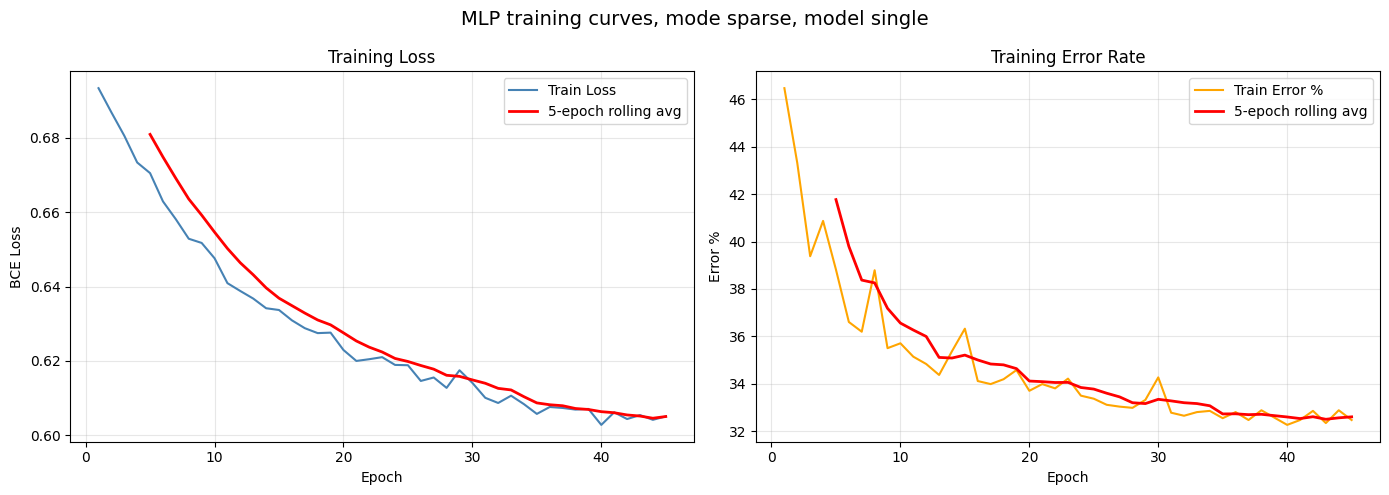

starting the model creation process 
here are the amx featuerts  1000
Training MLP
************************************
  t=0.50 | Sensitivity: 73.7% | Specificity: 74.5% | FN: 128 | FP: 71
  t=0.30 | Sensitivity: 79.8% | Specificity: 61.5% | FN: 98 | FP: 107
  t=0.20 | Sensitivity: 86.4% | Specificity: 47.8% | FN: 66 | FP: 145
  t=0.10 | Sensitivity: 92.8% | Specificity: 33.1% | FN: 35 | FP: 186
  t=0.05 | Sensitivity: 97.7% | Specificity: 21.6% | FN: 11 | FP: 218
Test Accuracy : 74.0%
Test AUC-ROC  : 0.8271

Confusion Matrix:
  True Negatives  (correctly said normal)   : 60
  False Positives (incorrectly flagged)      : 218
  False Negatives (missed abnormal cases)   : 11  ← this is the dangerous one
  True Positives  (correctly caught)         : 475

Sensitivity (recall on positives): 97.7%
Specificity (recall on negatives): 21.6%


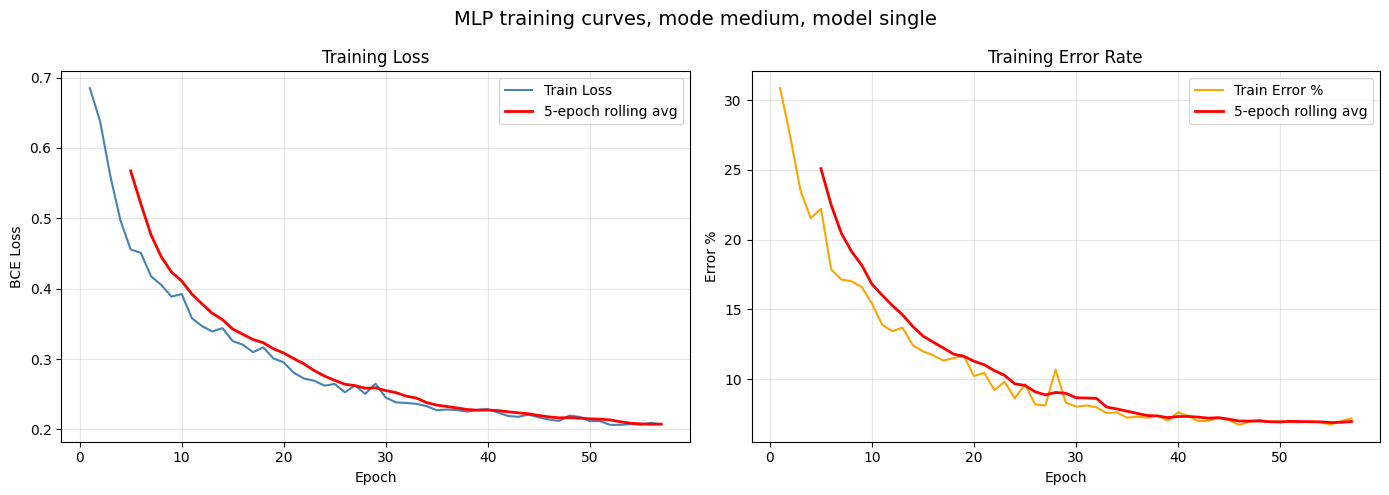

starting the model creation process 
here are the amx featuerts  500
Training MLP
************************************
  t=0.50 | Sensitivity: 94.2% | Specificity: 95.7% | FN: 28 | FP: 12
  t=0.30 | Sensitivity: 96.1% | Specificity: 94.2% | FN: 19 | FP: 16
  t=0.20 | Sensitivity: 96.9% | Specificity: 93.2% | FN: 15 | FP: 19
  t=0.10 | Sensitivity: 97.5% | Specificity: 89.6% | FN: 12 | FP: 29
  t=0.05 | Sensitivity: 98.8% | Specificity: 85.3% | FN: 6 | FP: 41
Test Accuracy : 94.8%
Test AUC-ROC  : 0.9840

Confusion Matrix:
  True Negatives  (correctly said normal)   : 237
  False Positives (incorrectly flagged)      : 41
  False Negatives (missed abnormal cases)   : 6  ← this is the dangerous one
  True Positives  (correctly caught)         : 480

Sensitivity (recall on positives): 98.8%
Specificity (recall on negatives): 85.3%


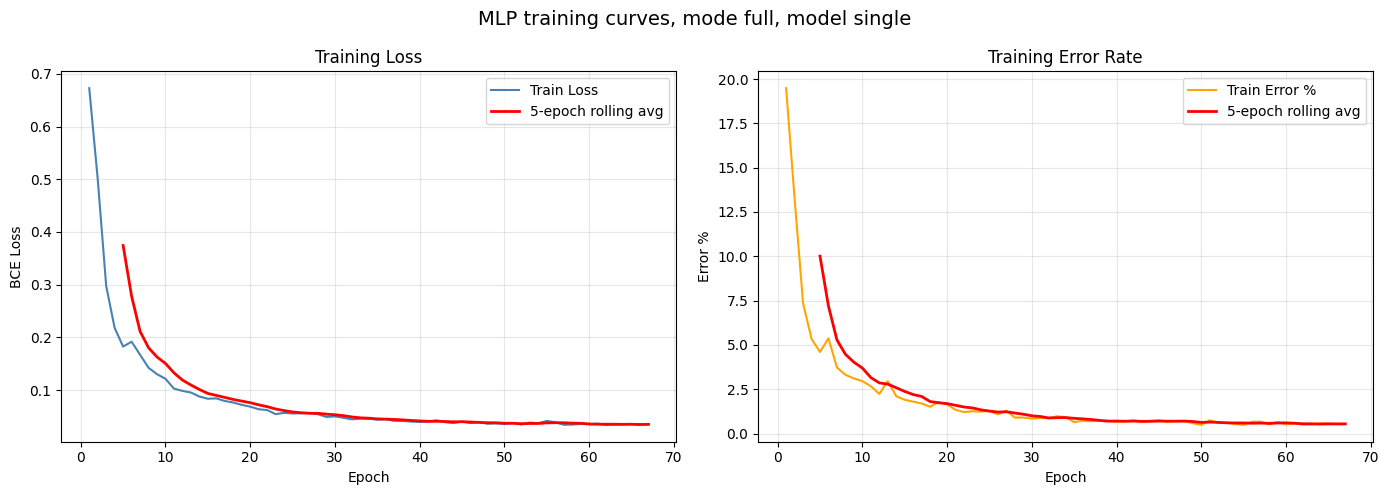

In [ ]:
# print("Creating the MLP")
# # ok now we have to do the freaking NLP stuff in an attempt to understand this better.
# modes = ["sparse", "medium", "full"]
# modes = ["medium"]


# xgb = XGBClassifier(n_estimators=500, scale_pos_weight=3, random_state=42)
# xgb.fit(X_train_np, y_train_np)
# print(f"XGB AUC: {roc_auc_score(y_test_np, xgb.predict_proba(X_test_np)[:,1]):.4f}")
#
# model_type = "ensemble"
# ensemble_probs, _, _, _, _ = create_mlp_model(df, modes[0], model_type)
# print(f"Ensemble AUC: {roc_auc_score(y_test_np, ensemble_probs):.4f}")
#
# model_type = "single"
# model, errors_train, errors_test, losses_train, losses_test = create_mlp_model(df, modes[0], model_type)
# # plot_training_curves(losses_train, errors_train)

modes = ["sparse", "medium", "full"]
model_type = "single"
for mode in modes:
    print("Running model. Mode ", mode, " type ", model_type)
    model, errors_train, errors_test, losses_train, losses_test = create_mlp_model(df, mode, model_type)
